In [28]:
import pandas as pd
from sqlalchemy import create_engine

In [29]:
path = "data/heat_exchanger.db"

engine = create_engine(f"sqlite:///{path}")


df = pd.read_sql("SELECT * FROM heat_exchanger",engine)

df['timestamp'] = pd.to_datetime(df["timestamp"])
df['day_index'] = (df['timestamp'] - df['timestamp'].min()).dt.days
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   timestamp                 175 non-null    datetime64[us]
 1   water_inlet_temperature   175 non-null    float64       
 2   glycol_inlet_temperature  175 non-null    float64       
 3   out_glycol_temperature    175 non-null    float64       
 4   out_water_temperature     175 non-null    float64       
 5   heat_efficiency           175 non-null    float64       
 6   day_index                 175 non-null    int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 9.7 KB


In [30]:
df.isnull().sum()

timestamp                   0
water_inlet_temperature     0
glycol_inlet_temperature    0
out_glycol_temperature      0
out_water_temperature       0
heat_efficiency             0
day_index                   0
dtype: int64

In [31]:
df.describe()

,timestamp,water_inlet_temperature,glycol_inlet_temperature,out_glycol_temperature,out_water_temperature,heat_efficiency,day_index
count,175,175.000000,175.000000,175.000000,175.000000,175.000000,175.000000
mean,2025-12-27 08:21:56.571428,31.441943,69.699429,41.350343,51.461277,94.741801,89.348571
min,2025-09-29 00:00:00,20.850000,21.110000,20.700000,21.262971,93.225263,0.000000
25%,2025-11-11 12:00:00,30.910000,31.545000,31.565000,33.128821,93.921594,43.500000
50%,2025-12-27 00:00:00,32.100000,84.130000,45.580000,59.250579,94.691906,89.000000
75%,2026-02-10 12:00:00,32.770000,85.845000,46.485000,60.107158,95.536221,134.500000
max,2026-03-28 00:00:00,35.930000,89.180000,48.970000,64.060976,96.454517,180.000000
std,NaN,2.382263,24.781046,7.686540,13.872204,0.941302,52.465738


Text(0.5, 1.0, 'Heat Efficiency vs Day Index')

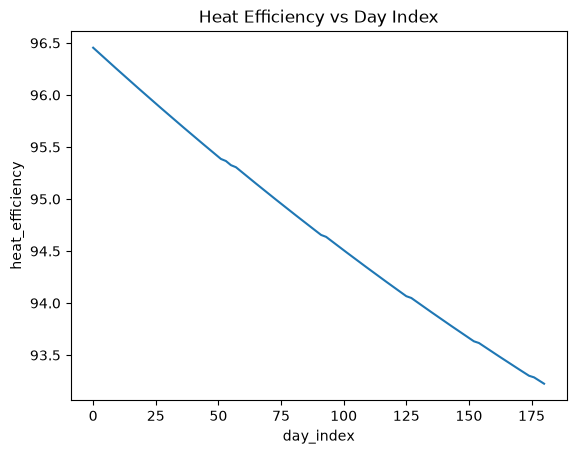

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.lineplot(df, x="day_index", y="heat_efficiency")
plt.title("Heat Efficiency vs Day Index")